# Selection-Adjusted False Discovery across Searched Trials

For one trial, the posterior probability that a reported discovery came from the null is:

$$
\operatorname{FDR}_1
=\frac{\alpha\pi_0}
{\alpha\pi_0+(1-\beta)(1-\pi_0)}.
$$

Here, $\alpha$ is the one-trial Type I error probability, $\beta$ is the one-trial Type II error probability, $\pi_0$ is the prior probability that the trial is null, and $\operatorname{FDR}_1$ is the null probability conditional on observing a discovery in that single trial.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("08_search_adjusted_portfolios");
using CSV, TOML, Printf, Distributions
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSearchStudy.jl"))
using .BookSearchStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter08_random_inputs"),"search")
captions=Dict("allocation_quickstart_weights"=>"Exact weights in the released three-asset example.","allocation_kkt_checks"=>"Exposure and first-order checks for the released allocation.","allocation_feasible_perturbations"=>"Variance along feasible changes around the optimum.","allocation_target_sweep"=>"Weights and variance as the second target exposure changes.","allocation_invariance_checks"=>"Changes of units and order that preserve the allocation identities.","allocation_square_system"=>"Square exposure systems have covariance-independent weights.","allocation_data_provenance"=>"Public data used for the constrained allocation example.","allocation_public_weights"=>"Weights under a budget constraint and two additional supplied exposure targets.","allocation_public_exposures"=>"Achieved exposures in the public covariance example.","allocation_public_summary"=>"Variance and weight summaries under the public covariance estimate.","allocation_public_target_sweep"=>"Risk and gross exposure as a supplied target changes.","allocation_condition_sensitivity"=>"Allocation behavior as two supplied exposure columns approach dependence.","allocation_input_checks"=>"Rejected inputs at the public allocation boundary.","allocation_public_surface"=>"Released public allocation material covered by Section 27.1.","allocation_section_summary"=>"Interpretation limits for target-exposure allocation.","misspecification_released_weights"=>"Weights in the released allocation diagnostic example.","misspecification_released_exposures"=>"Reference-system exposures in the released diagnostic example.","misspecification_released_variances"=>"Variance and declared-target checks for the two released allocations.","misspecification_source_weights"=>"Weights reported for the published two-asset confounder example.","misspecification_source_exposures"=>"Direct exposure arithmetic for the allocations reported in the published confounder example.","misspecification_source_variances"=>"Arithmetic checks for the weights reported in the published confounder example.","misspecification_data_provenance"=>"Public covariance data used for the allocation comparison.","misspecification_public_weights"=>"Weights obtained from two supplied exposure systems under the same public covariance.","misspecification_public_exposures"=>"Reference-system exposure errors under the perturbed supplied system.","misspecification_public_summary"=>"Summary of the public covariance allocation comparison.","misspecification_perturbation_summary"=>"Average diagnostics across 30 fixed-seed exposure perturbations.","misspecification_worst_cases"=>"Ten largest exposure errors in the repeated experiment.","misspecification_invariance"=>"Covariance-unit checks for allocation diagnostics.","misspecification_sign_boundaries"=>"Strict sign-reversal rule at and away from zero.","misspecification_input_checks"=>"Rejected inputs at the public diagnostic boundary.","misspecification_record_checks"=>"Immutability checks for returned diagnostic evidence.","misspecification_public_surface"=>"Released public diagnostic material covered by Section 27.2.","misspecification_section_summary"=>"Interpretation of the allocation diagnostics.","fdr_single_trial_bayes"=>"Four-state probability table for the published one-trial case.","fdr_single_trial_boundaries"=>"Boundary identities for the one-trial false discovery rate.","fdr_published_cases"=>"Published and sensitivity false discovery calculations.","fdr_search_count_grid"=>"Family probabilities as the number of searched trials changes.","fdr_threshold_grid"=>"Family error and false discovery calculations over reporting thresholds.","fdr_simulation_check"=>"Fixed-seed check of the maximum-selection distribution.","fdr_comparison_conditions"=>"Equality and inequality directions for one-trial and family false discovery rates.","fdr_conditional_tail"=>"Conditional upper-tail probabilities after maximum selection.","fdr_gaussian_thresholds"=>"Per-threshold Gaussian search-adjustment evidence under supplied parameters.","fdr_gaussian_aggregate"=>"Aggregate Gaussian calculation under supplied parameters.","fdr_likelihood_check"=>"Likelihood checks for supplied selected observations.","fdr_nonidentification_witness"=>"Different false discovery rates that reconstruct the same selected cumulative probability.","fdr_selection_level"=>"Family and selected-winner null probabilities under supplied Gaussian parameters.","fdr_input_checks"=>"Rejected inputs at the public false discovery boundary.","fdr_record_checks"=>"Immutability checks for returned false discovery evidence.","fdr_public_surface"=>"Released public search-adjustment material covered by Section 27.3.","fdr_section_summary"=>"The distinct questions answered by the Chapter 27 false discovery calculations.");


## Example settings and comparison cases

In [1]:
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim8-"*replace(name,"_"=>"-"))
    return nothing
end
case_b_alpha=.024997895148220373
case_b_beta=.9515427737332771
case_b_null=.15
case_b_fdr=single_trial_false_discovery_rate(case_b_alpha,case_b_beta,case_b_null)
bayes_table=frame(["Latent state","Decision","Joint probability","Included in discoveries","False discovery"],[("Null","Discovery",case_b_null*case_b_alpha,true,true),("Null","No discovery",case_b_null*(1-case_b_alpha),false,false),("Alternative","Discovery",(1-case_b_null)*(1-case_b_beta),true,false),("Alternative","No discovery",(1-case_b_null)*case_b_beta,false,false)])
table(bayes_table,"fdr_single_trial_bayes")
boundary_cases=[(0.,.2,.7),(.2,1.,.7),(.4,.6,.5),(1.,0.,0.),(1.,1.,1.)]
boundary_table=frame(["Type I error","Type II error","Trial null probability","Single-trial false discovery rate"],[(alpha,beta,prior,single_trial_false_discovery_rate(alpha,beta,prior)) for (alpha,beta,prior) in boundary_cases])
table(boundary_table,"fdr_single_trial_boundaries")


Row,Latent state,Decision,Joint probability,Included in discoveries,False discovery
,String,String,Float64,String,String
1,Null,Discovery,0.00374968,Yes,Yes
2,Null,No discovery,0.14625,No,No
3,Alternative,Discovery,0.0411886,Yes,No
4,Alternative,No discovery,0.808811,No,No


Row,Type I error,Type II error,Trial null probability,Single-trial false discovery rate
,Float64,Float64,Float64,Float64
1,0.0,0.2,0.7,0.0
2,0.2,1.0,0.7,1.0
3,0.4,0.6,0.5,0.5
4,1.0,0.0,0.0,0.0
5,1.0,1.0,1.0,1.0


## How a searched family changes error probabilities

For a searched family of $K$ independent trials, the family null probability and family false discovery rate are:

$$
\pi_F=\pi_0^K,
\qquad
\operatorname{FDR}_F
=\frac{\alpha_F\pi_F}
{\alpha_F\pi_F+(1-\beta_F)(1-\pi_F)}.
$$

Here, $K$ is the number of searched trials, $\pi_F$ is the probability that all $K$ trials are null, $\alpha_F$ is the family Type I error probability, $\beta_F$ is the family Type II error probability conditional on a family containing at least one alternative, and $\operatorname{FDR}_F$ is the family-level posterior null probability after a discovery.

Row,Case,Trials,Trial null probability,Family null probability,Type I error,Type II error,False discovery rate
,String,Int64,Float64,Float64,Float64,Float64,Float64
1,One reported trial,1,0.15,0.15,0.0249979,0.951543,0.0834407
2,Published search case,10,0.95,0.598737,0.223654,0.753196,0.57486
3,Sensitivity case,5,0.9,0.59049,0.226219,0.724577,0.542196


Row,Trials,Family null probability,Family Type I error,Family Type II error,Family false discovery rate
,Int64,Float64,Float64,Float64,Float64
1,1,0.95,0.0249979,0.951543,0.907421
2,2,0.9025,0.0493709,0.927184,0.862563
3,5,0.773781,0.118895,0.857733,0.740836
4,10,0.598737,0.223654,0.753196,0.57486
5,20,0.358486,0.397286,0.580365,0.346
6,50,0.076945,0.717981,0.264172,0.0752191


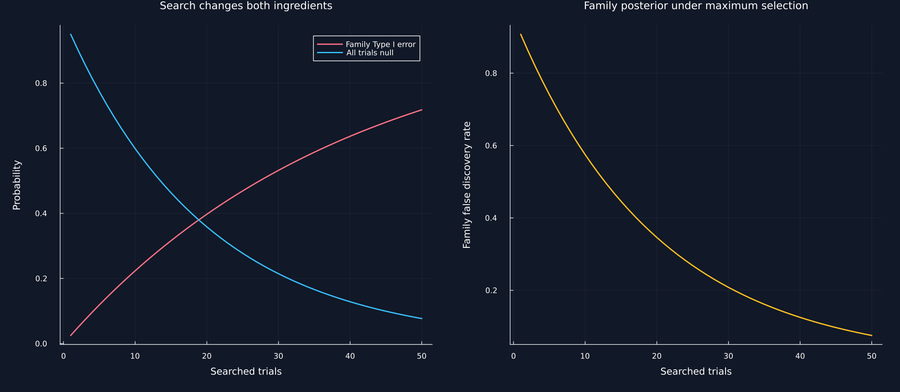

In [2]:
case_a_null=.95
case_a_trials=10
case_a_errors=max_selection_family_errors(case_b_alpha,case_b_beta,case_a_null,case_a_trials)
case_a_fdr=family_level_false_discovery_rate(case_a_errors.family_type_i_error,case_a_errors.family_type_ii_error,case_a_null,case_a_trials)
sensitivity_errors=max_selection_family_errors(.05,.90,.90,5)
sensitivity_fdr=family_level_false_discovery_rate(sensitivity_errors.family_type_i_error,sensitivity_errors.family_type_ii_error,.90,5)
published_table=frame(["Case","Trials","Trial null probability","Family null probability","Type I error","Type II error","False discovery rate"],[("One reported trial",1,case_b_null,case_b_null,case_b_alpha,case_b_beta,case_b_fdr),("Published search case",case_a_trials,case_a_null,case_a_errors.family_null_probability,case_a_errors.family_type_i_error,case_a_errors.family_type_ii_error,case_a_fdr),("Sensitivity case",5,.90,sensitivity_errors.family_null_probability,sensitivity_errors.family_type_i_error,sensitivity_errors.family_type_ii_error,sensitivity_fdr)])
table(published_table,"fdr_published_cases")
search_rows=[]
for trials in 1:50
    errors=max_selection_family_errors(case_b_alpha,case_b_beta,case_a_null,trials)
    family_fdr=family_level_false_discovery_rate(errors.family_type_i_error,errors.family_type_ii_error,case_a_null,trials)
    push!(search_rows,(trials,errors.family_null_probability,errors.family_type_i_error,errors.family_type_ii_error,family_fdr))
end
search_frame=frame(["Trials","Family null probability","Family Type I error","Family Type II error","Family false discovery rate"],search_rows)
table(search_frame[in.(search_frame.Trials,Ref([1,2,5,10,20,50])),:],"fdr_search_count_grid")
save_data(search_frame,paths,"fdr_search_count_paths")
left=plot(search_frame.Trials,search_frame[:,3];color=palette.rose,label="Family Type I error",xlabel="Searched trials",ylabel="Probability",title="Search changes both ingredients")
plot!(left,search_frame.Trials,search_frame[:,2];color=palette.cyan,label="All trials null")
right=plot(search_frame.Trials,search_frame[:,5];color=palette.amber,label="",xlabel="Searched trials",ylabel="Family false discovery rate",title="Family posterior under maximum selection")
save_figure(plot(left,right;layout=(1,2),size=(1400,610)),paths,"fdr_search_count_paths")


## Maximum Selection Uses the Maximum of Trial Mixtures

The distribution of the selected maximum and its family error probabilities are:

$$
H_K(z)=\{\pi_0F_0(z)+(1-\pi_0)F_1(z)\}^{K},
\qquad
\alpha_F=1-(1-\alpha)^K,
\qquad
\beta_F=\frac{[\pi_0(1-\alpha)+(1-\pi_0)\beta]^K-[\pi_0(1-\alpha)]^K}{1-\pi_0^K}.
$$

Here, $F_0$ and $F_1$ are the one-trial null and alternative cumulative distributions, $H_K$ is the cumulative distribution of the maximum across $K$ trial mixtures, and $\alpha$, $\beta$, $\pi_0$, $\alpha_F$, and $\beta_F$ have their one-trial and family meanings defined above.

### Distribution of the maximum of trial mixtures

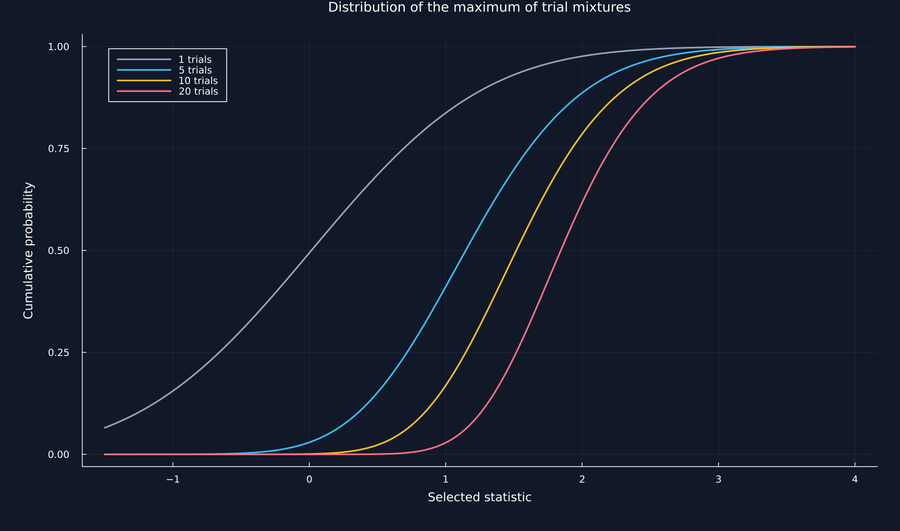

Row,Threshold,Trial Type I error,Trial Type II error,Family Type I error,Family Type II error,Family false discovery rate
,Float64,Float64,Float64,Float64,Float64,Float64
1,1.64,0.0505026,0.909877,0.404423,0.564899,0.581051
2,1.96,0.0249979,0.951543,0.223654,0.753196,0.57486
3,2.33,0.00990308,0.978822,0.0947321,0.892455,0.567915
4,3.09,0.00100078,0.997365,0.00996287,0.988019,0.553735


In [3]:
gaussian_model=GaussianTrialMixture(.95,1.,.3,1.)
cdf_grid=collect(range(-1.5,4.;length=300))
cdf_data=DataFrame("Selected statistic"=>cdf_grid)
figure=plot(;xlabel="Selected statistic",ylabel="Cumulative probability",title="Distribution of the maximum of trial mixtures",size=(1100,650))
for (trials,color) in zip([1,5,10,20],[muted,palette.cyan,palette.amber,palette.rose])
    values=[gaussian_max_selection_cdf(gaussian_model,value,trials) for value in cdf_grid]
    cdf_data[!,string(trials)*" trials"]=values
    plot!(figure,cdf_grid,values;color=color,label=string(trials)*" trials")
end
save_data(cdf_data,paths,"fdr_maximum_cdf")
save_figure(figure,paths,"fdr_maximum_cdf")
threshold_rows=[]
for threshold in [1.64,1.96,2.33,3.09]
    alpha=ccdf(Normal(),threshold)
    beta=cdf(Normal(),threshold-gaussian_model.alternative_mean)
    errors=max_selection_family_errors(alpha,beta,gaussian_model.trial_null_probability,10)
    family_fdr=family_level_false_discovery_rate(errors.family_type_i_error,errors.family_type_ii_error,gaussian_model.trial_null_probability,10)
    push!(threshold_rows,(threshold,alpha,beta,errors.family_type_i_error,errors.family_type_ii_error,family_fdr))
end
threshold_table=frame(["Threshold","Trial Type I error","Trial Type II error","Family Type I error","Family Type II error","Family false discovery rate"],threshold_rows)
table(threshold_table,"fdr_threshold_grid");


### Generated maxima agree with the analytical distribution

Row,Threshold,Analytical cumulative probability,Generated cumulative probability,Absolute difference,Two-standard-error allowance
,Float64,Float64,Float64,Float64,Float64
1,-0.5,6.6757e-6,0.0,6.6757e-6,1.63409e-5
2,0.0,0.000867336,0.00096,9.26638e-5,0.000186181
3,1.0,0.169116,0.16839,0.000726098,0.00237079
4,1.96,0.767057,0.76782,0.000762976,0.00267343
5,3.0,0.985537,0.98509,0.000447477,0.000755072


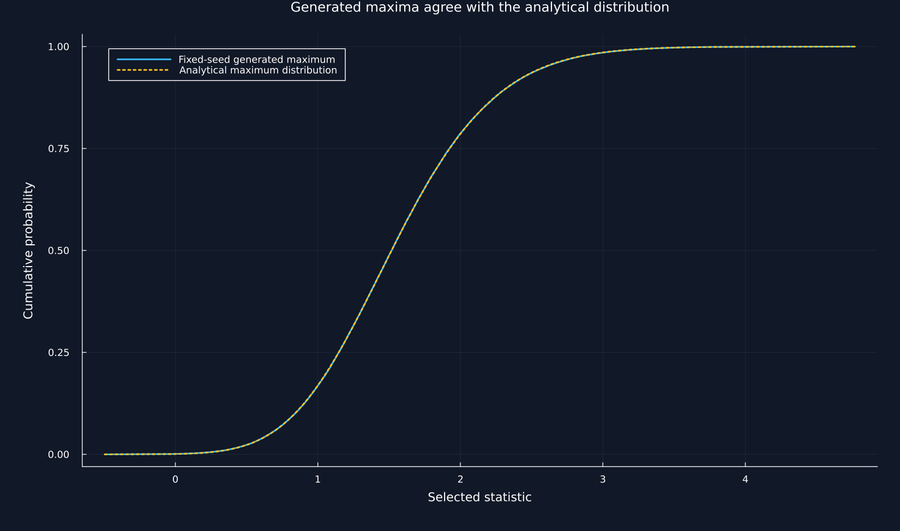

In [3]:
simulation_count=100000
simulation_trials=10
simulated_nulls=normal_block(store,"null_uniform").<gaussian_model.trial_null_probability
simulated_values=normal_block(store,"normal").+ifelse.(simulated_nulls,0.,gaussian_model.alternative_mean)
simulated_maxima=vec(maximum(simulated_values;dims=2))
simulation_rows=[]
for threshold in [-.5,0.,1.,1.96,3.]
    analytical=gaussian_max_selection_cdf(gaussian_model,threshold,simulation_trials)
    empirical=mean(simulated_maxima.<=threshold)
    standard_error=sqrt(analytical*(1-analytical)/simulation_count)
    push!(simulation_rows,(threshold,analytical,empirical,abs(empirical-analytical),2standard_error))
end
simulation_table=frame(["Threshold","Analytical cumulative probability","Generated cumulative probability","Absolute difference","Two-standard-error allowance"],simulation_rows)
table(simulation_table,"fdr_simulation_check")
save_data(DataFrame("Maximum"=>simulated_maxima,"Null trials"=>vec(sum(simulated_nulls;dims=2))),paths,"fdr_all_generated_maxima")
sorted_maxima=sort(simulated_maxima)
empirical_probabilities=collect(1:simulation_count)/simulation_count
selected_points=floor.(Int,range(0,simulation_count-1;length=1200)).+1
analytical_curve=[gaussian_max_selection_cdf(gaussian_model,value,simulation_trials) for value in sorted_maxima[selected_points]]
save_data(DataFrame("Maximum"=>sorted_maxima[selected_points],"Generated CDF"=>empirical_probabilities[selected_points],"Analytical CDF"=>analytical_curve),paths,"fdr_simulation_check")
figure=plot(sorted_maxima[selected_points],empirical_probabilities[selected_points];color=palette.cyan,label="Fixed-seed generated maximum",xlabel="Selected statistic",ylabel="Cumulative probability",title="Generated maxima agree with the analytical distribution",size=(1100,650))
plot!(figure,sorted_maxima[selected_points],analytical_curve;color=palette.amber,linestyle=:dot,label="Analytical maximum distribution")
save_figure(figure,paths,"fdr_simulation_check")


## Comparing conditional tail risks

After selection above a threshold $c$, the upper-tail probability at $x\geq c$ is:

$$
\Pr(Z\geq x\mid Z\geq c)
=\frac{1-F_Z(x)}{1-F_Z(c)}.
$$

Here, $Z$ is the reported statistic under the distribution being examined, $F_Z$ is its cumulative distribution, $c$ is the selection threshold, and $x$ is a value at least as large as $c$.

Row,Case,Family Type I error,Equation log gap,Single-trial false discovery rate,Family false discovery rate,Equality holds,Single-trial value is an upper bound
,String,Float64,Float64,Float64,Float64,String,String
1,Below equality,0.07875,-0.223144,0.2,0.166667,No,Yes
2,Equality,0.0984375,-4.44089e-16,0.2,0.2,Yes,Yes
3,Above equality,0.118125,0.182322,0.2,0.230769,No,No


Row,Trials,Selection threshold,Reported value,Conditional upper-tail probability
,Int64,Float64,Float64,Float64
1,1,1.96,2.0,0.910971
2,1,1.96,2.5,0.251973
3,1,1.96,3.0,0.0556249
4,1,1.96,3.5,0.00975721
5,10,1.96,2.0,0.920361
6,10,1.96,2.5,0.274834
7,10,1.96,3.0,0.0620861
8,10,1.96,3.5,0.0109495
9,50,1.96,2.0,0.954112


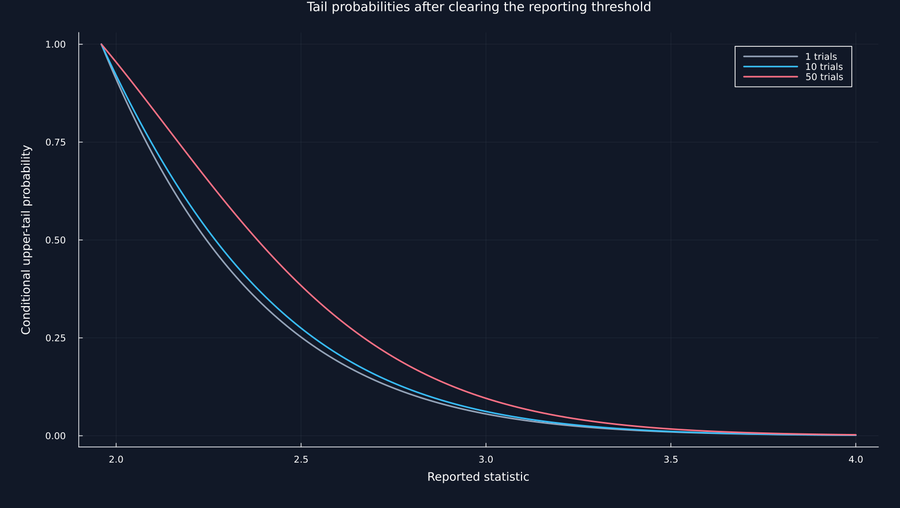

In [4]:
comparison_alpha=.05
comparison_beta=.20
comparison_prior=.80
comparison_trials=2
comparison_family_beta=.30
required_ratio=(1-comparison_family_beta)/(1-comparison_beta)*(1-comparison_prior^comparison_trials)/(comparison_prior^(comparison_trials-1)*(1-comparison_prior))
equality_alpha=comparison_alpha*required_ratio
comparison_rows=[]
for (name,family_alpha) in [("Below equality",.8equality_alpha),("Equality",equality_alpha),("Above equality",1.2equality_alpha)]
    evidence=compare_single_and_family_fdr(comparison_alpha,comparison_beta,comparison_prior,comparison_trials;family_type_i_error=family_alpha,family_type_ii_error=comparison_family_beta)
    push!(comparison_rows,(name,family_alpha,evidence.equation_13_log_gap,evidence.single_trial_false_discovery_rate,evidence.family_level_false_discovery_rate,evidence.identification_condition_holds,evidence.single_trial_upper_bounds_family))
end
comparison_table=frame(["Case","Family Type I error","Equation log gap","Single-trial false discovery rate","Family false discovery rate","Equality holds","Single-trial value is an upper bound"],comparison_rows)
table(comparison_table,"fdr_comparison_conditions")
conditional_rows=[]
selection_threshold=1.96
for trials in [1,10,50]
    cdf_at_threshold=gaussian_max_selection_cdf(gaussian_model,selection_threshold,trials)
    for value in [2.,2.5,3.,3.5]
        cdf_at_value=gaussian_max_selection_cdf(gaussian_model,value,trials)
        push!(conditional_rows,(trials,selection_threshold,value,conditional_upper_tail_probability(cdf_at_value,cdf_at_threshold)))
    end
end
conditional_table=frame(["Trials","Selection threshold","Reported value","Conditional upper-tail probability"],conditional_rows)
table(conditional_table,"fdr_conditional_tail")
conditional_grid=collect(range(selection_threshold,4.;length=180))
conditional_data=DataFrame("Reported statistic"=>conditional_grid)
figure=plot(;xlabel="Reported statistic",ylabel="Conditional upper-tail probability",title="Tail probabilities after clearing the reporting threshold",size=(1150,650))
for (trials,color) in zip([1,10,50],[muted,palette.cyan,palette.rose])
    threshold_cdf=gaussian_max_selection_cdf(gaussian_model,selection_threshold,trials)
    tail_values=[conditional_upper_tail_probability(gaussian_max_selection_cdf(gaussian_model,value,trials),threshold_cdf) for value in conditional_grid]
    conditional_data[!,string(trials)*" trials"]=tail_values
    plot!(figure,conditional_grid,tail_values;color=color,label=string(trials)*" trials")
end
save_data(conditional_data,paths,"fdr_conditional_tail")
save_figure(figure,paths,"fdr_conditional_tail")


## Gaussian Calculations under Supplied Parameters

Under the supplied two-component Gaussian model, the one-trial mixture, selected-maximum density, and likelihood are:

$$
G(z)=\pi_0\Phi\!\left(\frac{z}{\sigma_0}\right)+(1-\pi_0)\Phi\!\left(\frac{z-\mu_1}{\sigma_1}\right),
\qquad
h_K(z)=K G(z)^{K-1}g(z),
\qquad
\ell=\sum_{i=1}^{n}\log h_K(z_i).
$$

Here, $\Phi$ is the standard-normal cumulative distribution, $\pi_0$ is the one-trial null probability, $\sigma_0$ is the null standard deviation, $\mu_1$ and $\sigma_1$ are the alternative mean and standard deviation, $G$ and $g$ are the mixture cumulative distribution and density, $h_K$ is the density of the maximum across $K$ trials, and $z_1,\ldots,z_n$ are supplied selected observations.

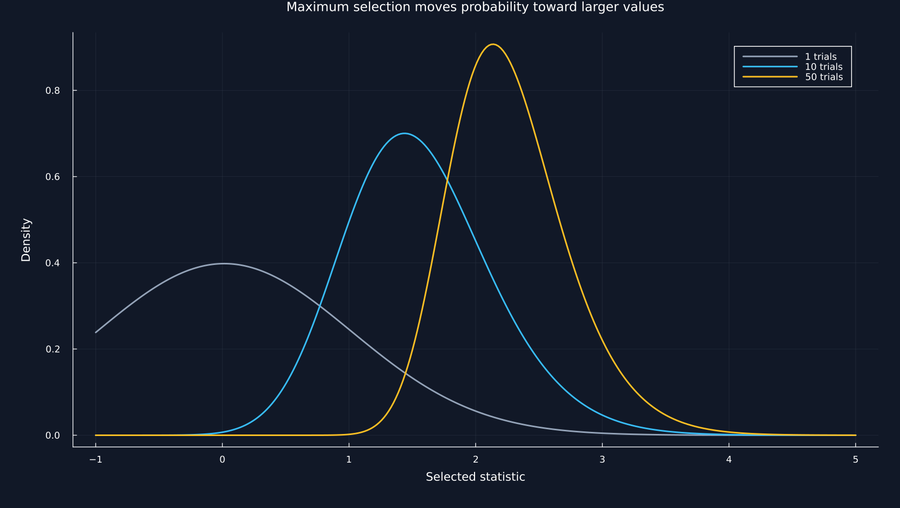

Row,Threshold,Trial Type I error,Trial Type II error,Family Type I error,Family Type II error
,Float64,Float64,Float64,Float64,Float64
1,1.64,0.0505026,0.909877,0.404423,0.564899
2,1.96,0.0249979,0.951543,0.223654,0.753196
3,2.33,0.00990308,0.978822,0.0947321,0.892455


Row,Quantity,Value
,String,Real
1,Trials,10
2,Family null probability,0.598737
3,Mean family Type I error,0.240936
4,Mean family Type II error,0.73685
5,Search-adjusted family false discovery rate,0.577377


Row,Calculation,Value,Difference from returned likelihood
,String,Float64,Float64
1,Sum of individual log densities,-12.381,0.0
2,Returned log likelihood,-12.381,0.0
3,Reversed observation order,-12.381,0.0


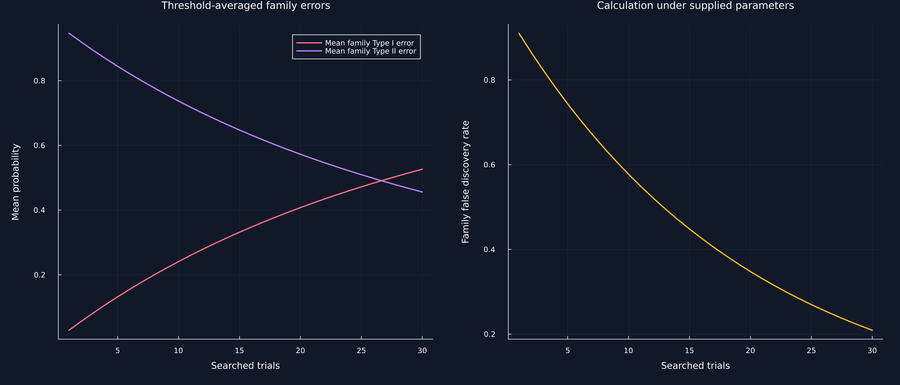

In [5]:
density_grid=collect(range(-1.,5.;length=320))
density_data=DataFrame("Selected statistic"=>density_grid)
figure=plot(;xlabel="Selected statistic",ylabel="Density",title="Maximum selection moves probability toward larger values",size=(1150,650))
for (trials,color) in zip([1,10,50],[muted,palette.cyan,palette.amber])
    densities=exp.([gaussian_max_selection_log_density(gaussian_model,value,trials) for value in density_grid])
    density_data[!,string(trials)*" trials"]=densities
    plot!(figure,density_grid,densities;color=color,label=string(trials)*" trials")
end
save_data(density_data,paths,"fdr_gaussian_density")
save_figure(figure,paths,"fdr_gaussian_density")
supplied_thresholds=[1.64,1.96,2.33]
gaussian_evidence=gaussian_search_adjusted_false_discovery_rate(gaussian_model,supplied_thresholds,10)
gaussian_threshold_table=DataFrame("Threshold"=>collect(gaussian_evidence.thresholds),"Trial Type I error"=>collect(gaussian_evidence.trial_type_i_errors),"Trial Type II error"=>collect(gaussian_evidence.trial_type_ii_errors),"Family Type I error"=>collect(gaussian_evidence.family_type_i_errors),"Family Type II error"=>collect(gaussian_evidence.family_type_ii_errors))
table(gaussian_threshold_table,"fdr_gaussian_thresholds")
gaussian_aggregate=frame(["Quantity","Value"],[("Trials",gaussian_evidence.n_trials),("Family null probability",gaussian_evidence.family_null_probability),("Mean family Type I error",gaussian_evidence.mean_family_type_i_error),("Mean family Type II error",gaussian_evidence.mean_family_type_ii_error),("Search-adjusted family false discovery rate",gaussian_evidence.false_discovery_rate)])
table(gaussian_aggregate,"fdr_gaussian_aggregate")
likelihood_observations=simulated_maxima[1:12]
direct_terms=[gaussian_max_selection_log_density(gaussian_model,value,simulation_trials) for value in likelihood_observations]
likelihood_value=gaussian_max_selection_log_likelihood(gaussian_model,likelihood_observations,simulation_trials)
permuted_likelihood=gaussian_max_selection_log_likelihood(gaussian_model,reverse(likelihood_observations),simulation_trials)
likelihood_table=frame(["Calculation","Value","Difference from returned likelihood"],[("Sum of individual log densities",sum(direct_terms),abs(sum(direct_terms)-likelihood_value)),("Returned log likelihood",likelihood_value,0.),("Reversed observation order",permuted_likelihood,abs(permuted_likelihood-likelihood_value))])
table(likelihood_table,"fdr_likelihood_check")
calibration_rows=[]
for trials in 1:30
    evidence=gaussian_search_adjusted_false_discovery_rate(gaussian_model,supplied_thresholds,trials)
    push!(calibration_rows,(trials,evidence.family_null_probability,evidence.mean_family_type_i_error,evidence.mean_family_type_ii_error,evidence.false_discovery_rate))
end
calibration_frame=frame(["Trials","Family null probability","Mean family Type I error","Mean family Type II error","Family false discovery rate"],calibration_rows)
save_data(calibration_frame,paths,"fdr_threshold_adjustment")
left=plot(calibration_frame.Trials,calibration_frame[:,3];color=palette.rose,label="Mean family Type I error",xlabel="Searched trials",ylabel="Mean probability",title="Threshold-averaged family errors")
plot!(left,calibration_frame.Trials,calibration_frame[:,4];color=violet,label="Mean family Type II error")
right=plot(calibration_frame.Trials,calibration_frame[:,5];color=palette.amber,label="",xlabel="Searched trials",ylabel="Family false discovery rate",title="Calculation under supplied parameters")
save_figure(plot(left,right;layout=(1,2),size=(1450,620)),paths,"fdr_threshold_adjustment")


## Nonidentification from Selected Statistics Alone

A two-trial witness can preserve one observed cumulative probability while assigning any interior target family false discovery rate:

$$
\pi_0=\sqrt q,
\qquad
G(c)=\sqrt h,
\qquad
\alpha_F=1-h,
\qquad
\beta_F=h,
\qquad
\operatorname{FDR}_F=q.
$$

Here, $h$ is the observed cumulative probability of the selected statistic at threshold $c$, $q$ is any chosen family false discovery rate strictly between zero and one, $\pi_0$ is the constructed trial null probability, and $G(c)$ is a latent one-trial cumulative probability whose square reconstructs $h$.

Row,Target family false discovery rate,Constructed trial null probability,Latent trial cumulative probability,Reconstructed observed cumulative probability,Returned family false discovery rate
,Float64,Float64,Float64,Float64,Float64
1,0.1,0.316228,0.8,0.64,0.1
2,0.3,0.547723,0.8,0.64,0.3
3,0.5,0.707107,0.8,0.64,0.5
4,0.8,0.894427,0.8,0.64,0.8
5,0.95,0.974679,0.8,0.64,0.95


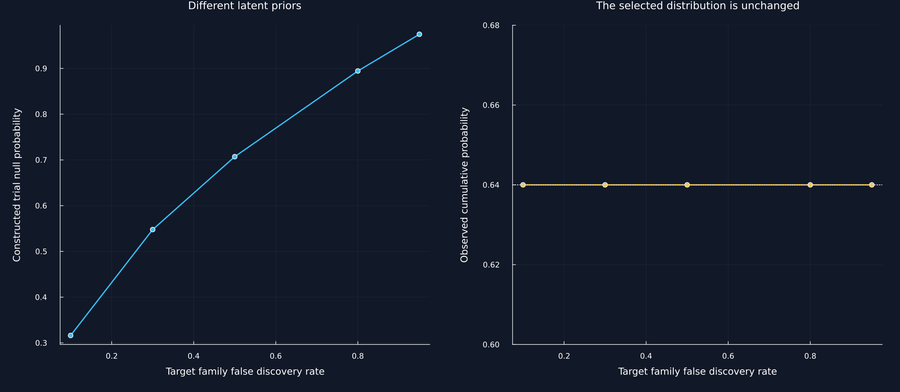

In [6]:
observable_cdf=.64
target_values=[.10,.30,.50,.80,.95]
witness_rows=[]
for target in target_values
    witness=fdr_nonidentification_witness(observable_cdf,target)
    push!(witness_rows,(witness.target_false_discovery_rate,witness.trial_null_probability,witness.latent_trial_cdf_at_threshold,witness.reconstructed_observable_cdf_at_threshold,witness.family_false_discovery_rate))
end
witness_table=frame(["Target family false discovery rate","Constructed trial null probability","Latent trial cumulative probability","Reconstructed observed cumulative probability","Returned family false discovery rate"],witness_rows)
table(witness_table,"fdr_nonidentification_witness")
left=plot(witness_table[:,1],witness_table[:,2];marker=:circle,color=palette.cyan,label="",xlabel="Target family false discovery rate",ylabel="Constructed trial null probability",title="Different latent priors")
right=plot(witness_table[:,1],witness_table[:,4];marker=:circle,color=palette.amber,label="",xlabel="Target family false discovery rate",ylabel="Observed cumulative probability",title="The selected distribution is unchanged")
hline!(right,[observable_cdf];color=palette.text,linestyle=:dot,linewidth=1.2,label="")
plot!(right;ylims=(.60,.68),yticks=([.60,.62,.64,.66,.68],["0.60","0.62","0.64","0.66","0.68"]))
save_figure(plot(left,right;layout=(1,2),size=(1400,610)),paths,"fdr_nonidentification")


## The Selected Winner Has a Stricter Null Probability

The probability that the selected winner is null, conditional on clearing threshold $c$, is:

$$
\Pr(H_{I^{\star}}=0\mid Z_{(K)}>c)
=\frac{K\pi_0\int_c^{\infty}f_0(z)G(z)^{K-1}\,dz}{1-G(c)^K}.
$$

Here, $I^{\star}$ labels the trial attaining the maximum $Z_{(K)}$, $H_{I^{\star}}=0$ means that winning trial is null, $f_0$ is the null density, $G$ is the one-trial mixture cumulative distribution, $K$ is the search count, $\pi_0$ is the trial null probability, and $c$ is the reporting threshold.

Row,Trials,Family false discovery rate,Selected-winner null probability,Selection probability,Family minus selected-winner value,Quadrature absolute error
,Int64,Float64,Float64,Float64,Float64,Float64
1,1,0.907421,0.907421,0.0261709,2.44249e-15,2.44078e-13
2,5,0.740836,0.907172,0.124182,-0.166336,2.26905e-12
3,10,0.57486,0.906857,0.232943,-0.331996,7.18581e-12
4,20,0.346,0.906216,0.411624,-0.560216,2.51348e-11
5,50,0.0752191,0.904251,0.734455,-0.829031,2.60236e-12


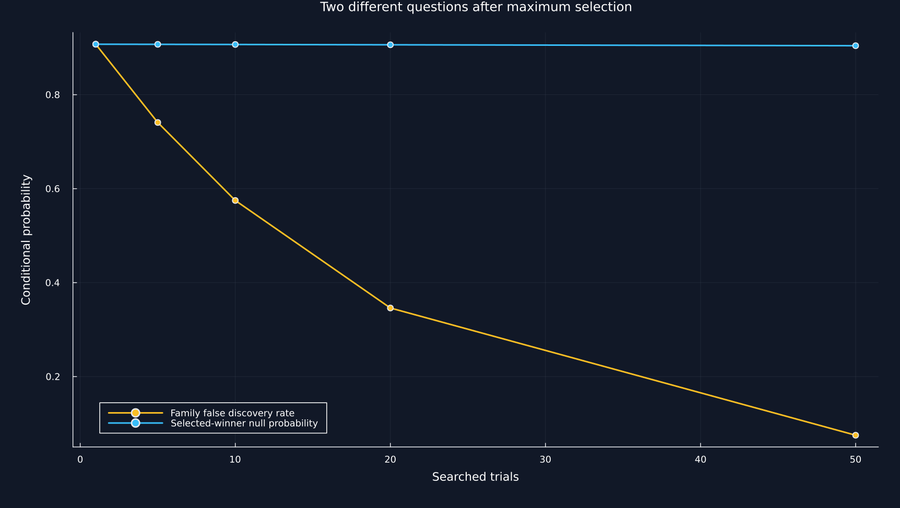

In [7]:
selected_threshold=1.96
selected_rows=[]
for trials in [1,5,10,20,50]
    alpha=ccdf(Normal(),selected_threshold)
    beta=cdf(Normal(),selected_threshold-gaussian_model.alternative_mean)
    errors=max_selection_family_errors(alpha,beta,gaussian_model.trial_null_probability,trials)
    family_fdr=family_level_false_discovery_rate(errors.family_type_i_error,errors.family_type_ii_error,gaussian_model.trial_null_probability,trials)
    selected=max_selection_null_probability(selected_threshold,gaussian_model.trial_null_probability,trials;null_density=value->normal_density(value,gaussian_model.null_standard_deviation),mixture_cdf=value->gaussian_trial_mixture_cdf(gaussian_model,value))
    push!(selected_rows,(trials,family_fdr,selected.conditional_null_probability,selected.selection_probability,family_fdr-selected.conditional_null_probability,selected.quadrature_absolute_error))
end
selected_table=frame(["Trials","Family false discovery rate","Selected-winner null probability","Selection probability","Family minus selected-winner value","Quadrature absolute error"],selected_rows)
table(selected_table,"fdr_selection_level")
figure=plot(selected_table.Trials,selected_table[:,2];marker=:circle,color=palette.amber,label="Family false discovery rate",xlabel="Searched trials",ylabel="Conditional probability",title="Two different questions after maximum selection",size=(1150,650))
plot!(figure,selected_table.Trials,selected_table[:,3];marker=:circle,color=palette.cyan,label="Selected-winner null probability")
save_figure(figure,paths,"fdr_family_vs_selection")


## Scope of the released calculations

In [8]:
input_checks=frame(["Check","Expected result","Observed result","Passed"],[contract_result("Probability below zero",()->single_trial_false_discovery_rate(-.1,.2,.7)),contract_result("Zero trial count",()->max_selection_family_errors(.05,.20,.70,0)),contract_result("Undefined discovery posterior",()->single_trial_false_discovery_rate(0.,1.,.5)),contract_result("Conditional cumulative values out of order",()->conditional_upper_tail_probability(.2,.4)),contract_result("Zero Gaussian scale",()->GaussianTrialMixture(.8,0.,1.,1.)),contract_result("Empty likelihood observations",()->gaussian_max_selection_log_likelihood(gaussian_model,Float64[],10)),contract_result("Boundary nonidentification target",()->fdr_nonidentification_witness(.4,0.)),contract_result("Negative supplied null density",()->max_selection_null_probability(0.,.5,2;null_density=value->-1.,mixture_cdf=value->.5))])
table(input_checks,"fdr_input_checks")
record_objects=[case_a_errors,compare_single_and_family_fdr(.05,.2,.8,2;family_type_i_error=equality_alpha,family_type_ii_error=.3),gaussian_model,gaussian_evidence,fdr_nonidentification_witness(.64,.3),max_selection_null_probability(1.96,.95,2;null_density=value->normal_density(value),mixture_cdf=value->gaussian_trial_mixture_cdf(gaussian_model,value))]
record_rows=[record_evidence(value) for value in record_objects]
record_rows[4]=record_evidence(gaussian_evidence;sources=(supplied_thresholds,))
record_table=frame(["Result record","Fields fixed","Array fields stored separately","Passed"],record_rows)
table(record_table,"fdr_record_checks")
public_surface = frame(["Public group","Count","Coverage"],[["False discovery result records",6,"Family errors, comparisons, Gaussian calculations, nonidentification, and selected-winner evidence"],["False discovery functions",13,"One trial, searched families, maximum selection, Gaussian calculations, likelihood, and witness"],["Released false discovery checks",42,"Identities, published cases, boundaries, oracles, numerical stability, and returned evidence"]])
table(public_surface,"fdr_public_surface")
section_summary = frame(["Quantity","Question","Required information"],[["One-trial false discovery rate","Was one reported trial null?","One-trial errors and one-trial null prior"],["Family false discovery rate","Was the entire searched family null?","Family errors, search count, and family null prior"],["Selected-winner null probability","Did the winning trial come from the null?","Null density, mixture distribution, threshold, and search count"],["Gaussian supplied-parameter calculation","What follows from a declared mixture?","Supplied mixture parameters and search count"]])
table(section_summary,"fdr_section_summary")


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Probability below zero,ArgumentError,ArgumentError,Yes
2,Zero trial count,ArgumentError,ArgumentError,Yes
3,Undefined discovery posterior,ArgumentError,ArgumentError,Yes
4,Conditional cumulative values out of order,ArgumentError,ArgumentError,Yes
5,Zero Gaussian scale,ArgumentError,ArgumentError,Yes
6,Empty likelihood observations,ArgumentError,ArgumentError,Yes
7,Boundary nonidentification target,ArgumentError,ArgumentError,Yes
8,Negative supplied null density,ArgumentError,ArgumentError,Yes


Row,Result record,Fields fixed,Array fields stored separately,Passed
,String,String,String,String
1,MaxSelectionFamilyErrors,Yes,Yes,Yes
2,FDRComparisonEvidence,Yes,Yes,Yes
3,GaussianTrialMixture,Yes,Yes,Yes
4,GaussianSearchAdjustedFDR,Yes,Yes,Yes
5,FDRNonIdentificationWitness,Yes,Yes,Yes
6,SelectionLevelProbabilityEvidence,Yes,Yes,Yes


Row,Public group,Count,Coverage
,String,Int64,String
1,False discovery result records,6,"Family errors, comparisons, Gaussian calculations, nonidentification, and selected-winner evidence"
2,False discovery functions,13,"One trial, searched families, maximum selection, Gaussian calculations, likelihood, and witness"
3,Released false discovery checks,42,"Identities, published cases, boundaries, oracles, numerical stability, and returned evidence"


Row,Quantity,Question,Required information
,String,String,String
1,One-trial false discovery rate,Was one reported trial null?,One-trial errors and one-trial null prior
2,Family false discovery rate,Was the entire searched family null?,"Family errors, search count, and family null prior"
3,Selected-winner null probability,Did the winning trial come from the null?,"Null density, mixture distribution, threshold, and search count"
4,Gaussian supplied-parameter calculation,What follows from a declared mixture?,Supplied mixture parameters and search count


## Tests

In [9]:
@assert allclose(case_b_fdr,.08344067427559432;rtol=2e-15,atol=1e-8)
@assert allclose(case_a_errors.family_type_i_error,.22365361940347483;rtol=2e-15,atol=1e-8)
@assert allclose(case_a_errors.family_type_ii_error,.7531960884251256;rtol=2e-15,atol=1e-8)
@assert allclose(case_a_errors.family_null_probability,.5987369392383787;rtol=2e-15,atol=1e-8)
@assert allclose(case_a_fdr,.5748603608683863;rtol=2e-15,atol=1e-8)
@assert all(simulation_table[:,4].<=simulation_table[:,5].+.0015)
@assert comparison_table[comparison_table.Case.=="Equality",6][1]
@assert allclose(likelihood_value,sum(direct_terms);rtol=1e-14,atol=1e-14)
@assert allclose(likelihood_value,permuted_likelihood;rtol=1e-14,atol=1e-14)
@assert allclose(witness_table[:,4],observable_cdf;rtol=1e-7,atol=2e-15)
@assert allclose(witness_table[:,5],witness_table[:,1];rtol=1e-7,atol=2e-15)
@assert all(0 .<=selected_table[:,2].<=1)
@assert all(0 .<=selected_table[:,3].<=1)
@assert all(0 .<=selected_table[:,4].<=1)
@assert allclose(selected_table[:,5],selected_table[:,2]-selected_table[:,3];rtol=1e-7,atol=2e-15)
@assert maximum(selected_table[:,6])<3e-10
@assert allclose(selected_table[selected_table.Trials.==1,2][1],selected_table[selected_table.Trials.==1,3][1];atol=1e-11)
@assert all(input_checks.Passed)
@assert all(record_table.Passed)
@assert sum(public_surface.Count)==61
@assert case_a_errors isa MaxSelectionFamilyErrors
@assert gaussian_evidence isa GaussianSearchAdjustedFDR
@assert all(name->isfile(joinpath(paths.figures,name*".pdf")),["fdr_search_count_paths","fdr_maximum_cdf","fdr_simulation_check","fdr_conditional_tail","fdr_gaussian_density","fdr_threshold_adjustment","fdr_nonidentification","fdr_family_vs_selection"])
@assert all(name->isfile(joinpath(paths.tables,name*".tex")),["fdr_single_trial_bayes","fdr_single_trial_boundaries","fdr_published_cases","fdr_search_count_grid","fdr_threshold_grid","fdr_simulation_check","fdr_comparison_conditions","fdr_conditional_tail","fdr_gaussian_thresholds","fdr_gaussian_aggregate","fdr_likelihood_check","fdr_nonidentification_witness","fdr_selection_level","fdr_input_checks","fdr_record_checks","fdr_public_surface","fdr_section_summary"])
